In [1]:
%cd ../.
import os, sys
sys.path.insert(0, os.path.abspath('../Scripts'))
sys.path.insert(0, os.path.expanduser('~/CDD_Vault_API/python'))  # CDD Vault API (get_df)

/home/gtamo/MS_ML


In [2]:
%load_ext autoreload
%autoreload 2

import re
import os
import pandas as pd
import numpy as np
import py3Dmol
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import csv
import pickle

from pathlib import Path
from rdkit import Chem
from rdkit.Chem import AllChem,rdFMCS
# import prolif as plf
from glob import glob
import meeko
import subprocess as sub
# from vina import Vina
import time
from tqdm.auto import tqdm  # auto -> notebook/VSCode widget
tqdm.pandas()
import importlib
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, silhouette_score, davies_bouldin_score, calinski_harabasz_score
from xgboost import XGBClassifier,XGBRegressor
from openTSNE import TSNE as oTSNE        # pip install openTSNE
import seaborn as sns
from scipy import stats
import pyarrow.dataset as pads
import csv, contextlib, threading, joblib
import joblib
from joblib import Parallel, delayed
from datetime import date

# user defined modules
import Rdkit_tools as rdkit_tools
importlib.reload(rdkit_tools)
import Molecule as M
import ML_Reg as ML_Reg
import ML_Class as ML_Class
from MolViz3D import MolViz3D
import Statistics_tools as stats_tools
import python.functions as fn
from get_library import get_df   # CDD Vault collection export
from python.MS_build_ML import PARAMS, DATA, OUTPUT   # CLI classes reused here (%autoreload picks up edits)
# from tdc.multi_pred import DTI

In [3]:
## params — every YAML key becomes an attribute (params.MS_PATH); Dropbox readers + MLTrail vault bound here
CONFIG = 'config/config.yaml'

params = PARAMS(CONFIG)
params.load_params()
params.setup_dropbox()    # params.dbx / params.dbx_glob per DROPBOX_BACKEND
params.load_registry()    # params.registry (shared MLTrail vault)

## transition shim — keeps the bare YAML names (SERAC_C, MS_PATH, ...) working in the cells below
globals().update({k: v for k, v in params.__dict__.items() if k.isupper()})
registry = params.registry
_dbx = _fbx_open = params.dbx
_fbx_glob = params.dbx_glob

print('> chemlib overwrite:', params.CHEMLIB_OVERWRITE, '| dfraw overwrite:', params.DFRAW_OVERWRITE)
print('> features:', params.FEATURES_TYPE)

> loaded 81 params from config/config.yaml
> Dropbox backend: rclone
> chemlib overwrite: False | dfraw overwrite: False
> features: H237


## 0. Imports

In [4]:
%%time
## data — library + proteomics + chemistry features (see python/MS_build_ML.py:DATA) - Lib ID, Lib Flavor, vector!
data = DATA()
data.load_chemical_lib_df(params)                                  # serac_df + validated / devalidated targets
## cm2rm now comes from config CM2RM_PARTS — any subset of contaminants (the CONTAMINANTS csv) |
## control_compounds (CONTROLS) | fbx_independent (Px_Ligase_dependent == 0 or Px_validated_WT == 0)
data.get_contaminants_and_controls(params)                         # parts=(...) here would override the config
data.load_proteomics_data(params)                                  # DFRAW_OVERWRITE -> rebuild from the tranches, else read the parquets
data.compute_features(params)                                      # FEATURES_TYPE -> MF_features (+ MF morgan bits)

## OpenTargets disease scores + the big-pharma-relevant subset (see python/MS_build_ML.py:DATA)
data.load_opentargets(params)   # ot_df, cached to OT_CACHE — delete that file to force a recompute from OT_ROOT
data.filter_pharma_targets()    # ot_pharma, via the module-level PHARMA_PRIORITY_AREAS / PHARMA_DROP_AREAS

## transition shim — bare names used by the cells below
serac_df, MS, df_raw, MF, MF_features = data.serac_df, data.MS, data.df_raw, data.MF, data.MF_features
control_compounds, contaminants, cm2rm = data.control_compounds, data.contaminants, data.cm2rm
fbx_independent = data.fbx_independent
validated_targets, devalidated_targets = data.validated_targets, data.devalidated_targets
ot_df, ot_pharma = data.ot_df, data.ot_pharma
# ot_df.to_csv('data/patent/20260609_OpenTarget_list.csv', sep=',', index=False)

> Chemical lib dim: (14168, 13) | 40 validated / 2772 devalidated targets
> 2 control + 81 contaminant compounds (from config) + 1026 fbx independent | cm2rm = contaminants = 81
> loaded cached MS (7222, 5) | df_raw (66186971, 12)
> DROP_CM2RM: dropped 38 compounds (381,674 df_raw rows) / 0 MS compounds
> MS derived from df_raw: 7,222 compounds | 153 change activity bin | 2 keep the delivered value (no df_raw row)
> checking smiles


100%|██████████| 14168/14168 [00:03<00:00, 4063.90it/s]


> FEATURES_TYPE: H237


H237 descriptors: 100%|██████████| 128/128 [00:08<00:00, 15.46it/s]


> 0 smiles failed | MF (14168, 2049) | MF_features (14086, 4470)
> loaded cached output/MS/opentargets_target_disease.parquet
> 232,004 (target, disease) rows / 11,584 targets resolved
> 78,935 / 232,004 (target, disease) rows pass the pharma filter | 9,105 unique targets
  17,071  cancer or benign tumor
   3,890  cardiovascular disease
   2,504  disorder of visual system
   3,466  endocrine system disease
   3,416  hematologic disease
   3,938  immune system disease
   3,710  infectious disease
   8,708  musculoskeletal or connective tissue disease
  25,393  nervous system disease
   9,849  nutritional or metabolic disease
   1,704  psychiatric disorder
   2,357  respiratory or thoracic disease
CPU times: user 1min 25s, sys: 30.4 s, total: 1min 55s
Wall time: 1min 38s


## 1. Analysis

In [5]:
## get compound by protein df:
VAL_PLATES = r'(?:WT|MLN|KO|BIND)$'   # validation plate suffixes, kept out of the primary screen
PROT_COL   = 'genes'                  # 'genes' = gene symbol, 'pg' = protein group
LIB_COLS   = ['smiles', 'Lib Flavor', 'Largest_Vector']   # serac_df columns joined on each compound

# primary-screen mask: the regex runs on the plate names, not on every row
val  = [p for p in df_raw['MSPlate'].dropna().unique() if re.search(VAL_PLATES, p, re.I)]
prim = ~df_raw['MSPlate'].isin(val) & df_raw[PROT_COL].notna()

# compounds the primary screen tested, with their library and activity summary
MS_prim = (MS[MS['compound'].isin(df_raw.loc[prim, 'compound'].unique())][['compound', 'date', 'ndown', 'activity']]
           .merge(serac_df[['compound'] + LIB_COLS].drop_duplicates('compound'), on='compound', how='left'))
print(MS_prim.shape)

# one column per protein hit at least once: 1 = significant and down for that compound
hit = df_raw[prim & (df_raw['significant'] == 1) & (df_raw['logfc'] < 0)]
mat = (pd.crosstab(hit['compound'], hit[PROT_COL]).clip(upper=1)
         .reindex(index=MS_prim['compound'], fill_value=0).astype('int8'))
cxp = MS_prim.set_index('compound').join(mat.loc[:, mat.any()])   #_> df=cols:[date,ndown,activity,smiles,Lib Flavor,Largest_Vector,TP53,...]

# cxp.head(3)

(7186, 7)


In [ ]:
## MS activity composition per library flavor
FROM_DATE = None     # e.g. '2026-10-06' to keep the recent tranches only
BAR_WIDTH = 0.6      # 1.0 = bars touching
COL2CLASS = {'Silent':         SERAC_C['paper'],
             'Single (1)':     SERAC_C['light_blue'],
             'Low (2-10)':     SERAC_C['sky_blue'],
             'Medium (11-25)': SERAC_C['terracotta'],
             'High (>25)':     SERAC_C['ember']}

# flavor cohorts of cxp, least active first, NaN dropped
d = cxp if FROM_DATE is None else cxp[cxp['date'] >= FROM_DATE]
flavors = d['activity'].ne('Silent').groupby(d['Lib Flavor']).mean().sort_values().index.tolist()

# one bar per flavor: height = % active, segments = the activity bins
ax, comp = fn.plot_activity_composition_bars(d[['Lib Flavor', 'activity']], group_col='Lib Flavor',
                                             order=flavors, normalize=True, show_silent=False,
                                             colors=COL2CLASS, width=BAR_WIDTH, dpi=150)
# comp

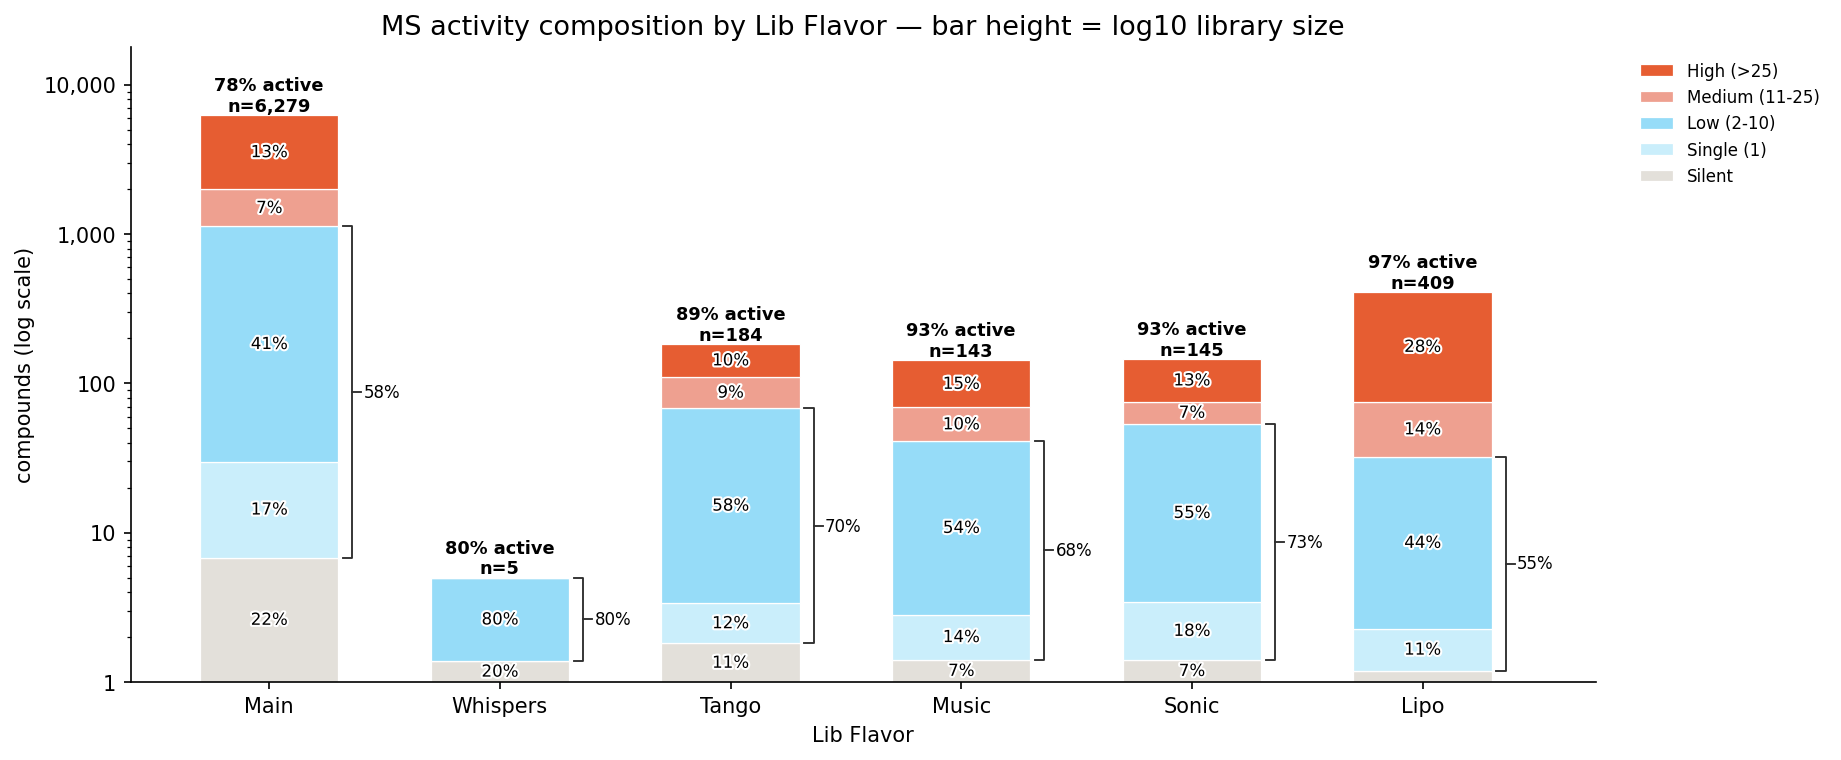

In [6]:
## MS activity composition per library flavor - adapted to lib size:
FROM_DATE = None     # e.g. '2026-10-06' to keep the recent tranches only
BAR_WIDTH = 0.6      # 1.0 = bars touching
BRACKET   = ('Single (1)', 'Low (2-10)')   # bins grouped beside each bar, with their summed share
COL2CLASS = {'Silent':         SERAC_C['paper'],
             'Single (1)':     SERAC_C['light_blue'],
             'Low (2-10)':     SERAC_C['sky_blue'],
             'Medium (11-25)': SERAC_C['terracotta'],
             'High (>25)':     SERAC_C['ember']}

# flavor cohorts of cxp, least active first, NaN dropped
d = cxp if FROM_DATE is None else cxp[cxp['date'] >= FROM_DATE]
flavors = d['activity'].ne('Silent').groupby(d['Lib Flavor']).mean().sort_values().index.tolist()

# one bar per flavor: height = log10 library size, segments = each bin's share, silent included
ax, comp = fn.plot_activity_composition_bars(d[['Lib Flavor', 'activity']], group_col='Lib Flavor',
                                             order=flavors, log_size=True, show_silent=True, bracket=BRACKET,
                                             colors=COL2CLASS, width=BAR_WIDTH, dpi=150)
# comp

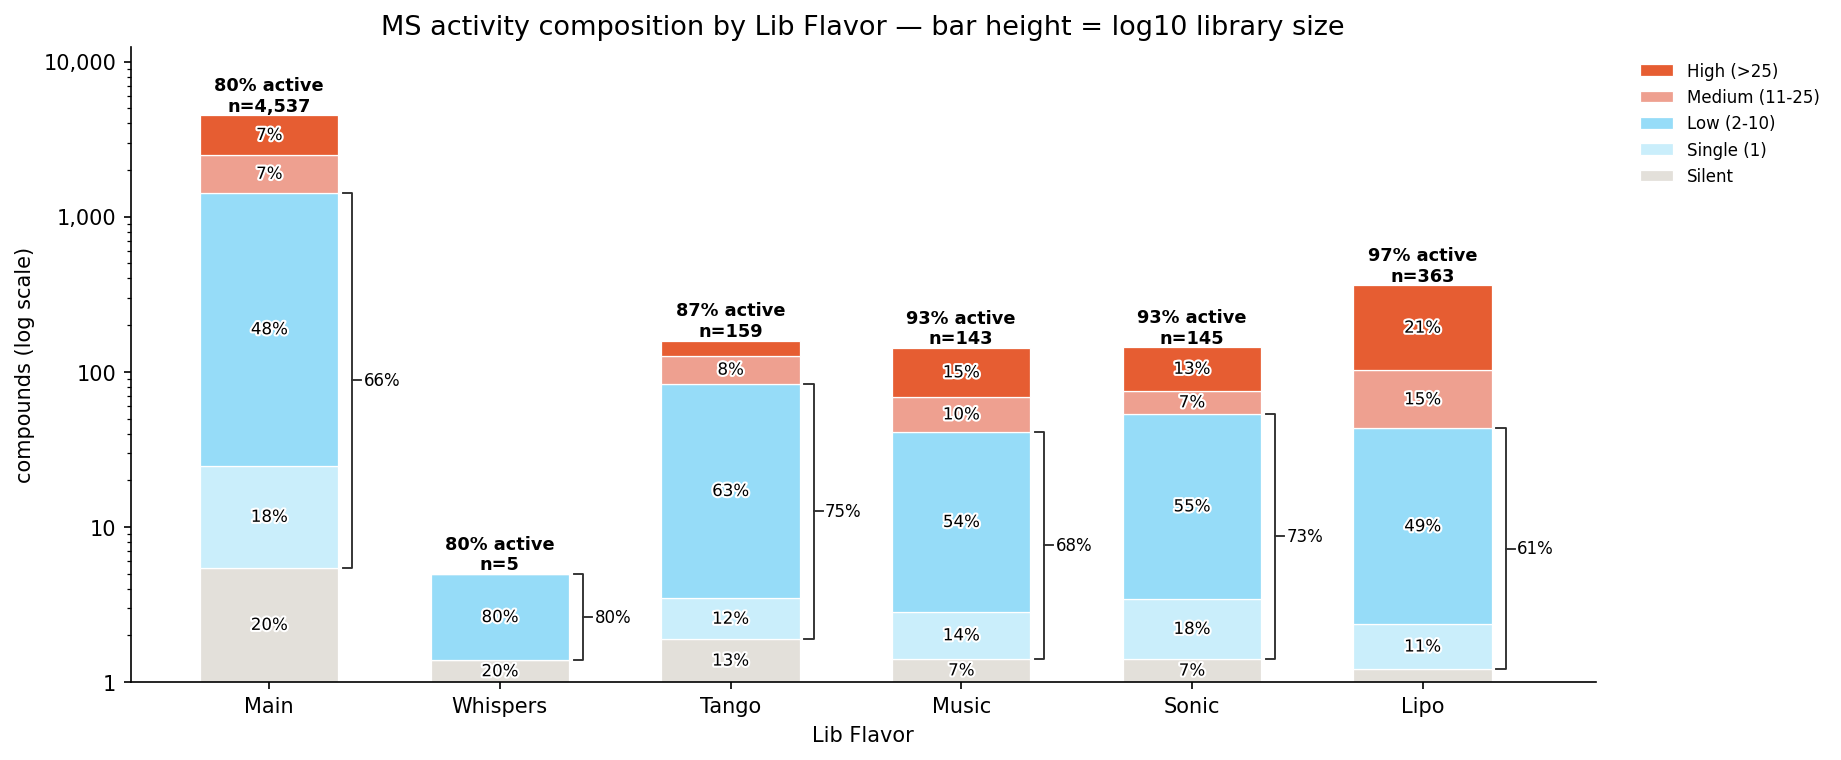

In [ ]:
## get hot target list: genes_ori = the name on the list, genes = the df_raw symbol
hot_df = pd.read_csv(params.HOT_TARGETS)
print(f'> hot targets: {hot_df.shape[0]:,} rows x {hot_df.shape[1]} cols')

In [ ]:
## Proteins hit by Single compounds
ACT_BINS  = ['Single (1)']   # activity bins the protein sets come from, e.g. + 'Low (2-10)'
MAIN      = 'Main'           # the large library, cut down to the flavored libraries' scale
MAIN_PART = None # 360              # Main compounds drawn at random, any activity; None keeps them all
SEED      = 2                # fixes the random draw
MAX_PATS  = 20               # intersection patterns drawn, biggest first
TOP_NAMES = 20               # protein names printed per pattern

# Main cut to MAIN_PART random compounds, so its protein set compares with the flavored ones
main = cxp[cxp['Lib Flavor'].eq(MAIN)]
d = pd.concat([cxp[cxp['Lib Flavor'].ne(MAIN)],
               main if MAIN_PART is None else main.sample(MAIN_PART, random_state=SEED)])

# one protein set per flavor, from the compounds of those bins only
d = d[d['activity'].isin(ACT_BINS) & d['Lib Flavor'].notna()]
fhit = d.select_dtypes('int8').groupby(d['Lib Flavor']).max()
sets = {f: fhit.columns[r.astype(bool)].tolist() for f, r in fhit.iterrows()}   #_> dict{list}={Lipo:[TP53,...],...}

# protein ranking: hot targets first, then descending disease association
hot = hot_df['genes'].unique()
rank = (pd.DataFrame({'hot': fhit.columns.isin(hot),
                      'assoc': ot_df.groupby('target_symbol')['overall_score'].max()
                                    .reindex(fhit.columns).fillna(0)}, index=fhit.columns)
        .sort_values(['hot', 'assoc'], ascending=False).index.tolist())

# upset: names = the best ranked proteins of each pattern, hot targets in ember
fig, inter = fn.plot_set_intersections(sets, max_patterns=MAX_PATS, names=TOP_NAMES, rank=rank,
                                       highlight=hot, highlight_color=SERAC_C['ember'], dpi=150)
inter

(5373, 4)


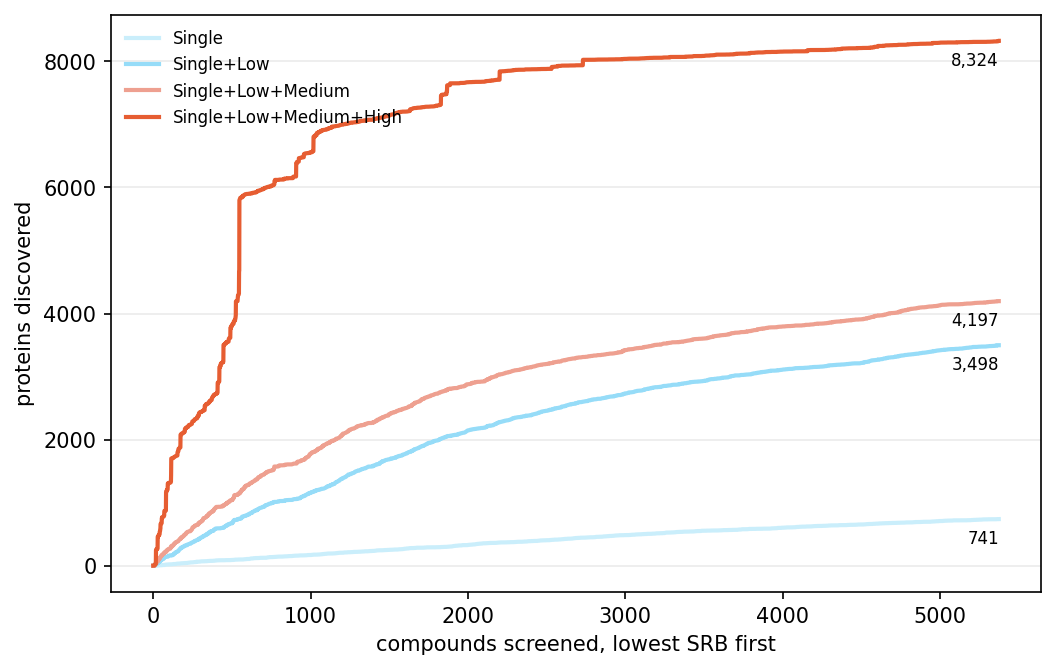

In [18]:
## Px Discovery evolution:
BINS     = ['Single (1)', 'Low (2-10)', 'Medium (11-25)', 'High (>25)']   # added one at a time, in this order
GRID_COL = '#EBEBEB'   # very light gray horizontal grid
DPI      = 150         # figure resolution

# compounds oldest first: the SRB number is the registration order
d = cxp.loc[cxp.index.to_series().str.extract(r'(\d+)', expand=False).astype(int).sort_values().index]
hitm = d.select_dtypes('int8').to_numpy().astype(bool)

# proteins discovered so far, one curve per cumulative bin set
disc = pd.DataFrame({'+'.join(b.split()[0] for b in BINS[:i + 1]):
                     np.logical_or.accumulate(hitm & d['activity'].isin(BINS[:i + 1]).to_numpy()[:, None]).sum(axis=1)
                     for i in range(len(BINS))}, index=np.arange(1, len(d) + 1))
print(disc.shape)

# one line per bin set, coloured by the bin it adds
fig, ax = plt.subplots(figsize=(8, 5), dpi=DPI)
disc.plot(ax=ax, color=[COL2CLASS[b] for b in BINS], lw=2)
ax.set(xlabel='compounds screened, lowest SRB first', ylabel='proteins discovered')

# legend and a light grid under the curves
ax.legend(frameon=False, fontsize=8, loc='upper left')
ax.grid(axis='y', color=GRID_COL, lw=0.8)
ax.set_axisbelow(True)

# the final count under each end point
for c in disc.columns:
    ax.annotate(f'{disc[c].iloc[-1]:,}', (len(disc), disc[c].iloc[-1]), fontsize=8,
                ha='right', va='top', xytext=(0, -5), textcoords='offset points')

# disc.tail(3)

Text(0.98, 0.04, '741 proteins discovered\n13.8 per 100 compounds on average\n8.0 per 100 compounds at the end (last 250)')

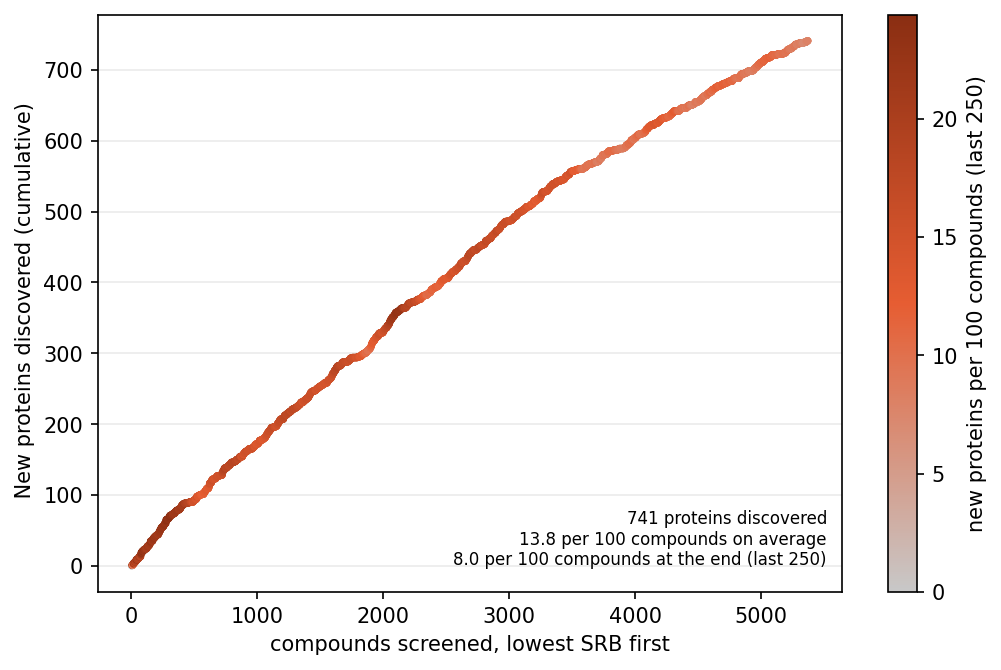

In [38]:
## Px Discovery evolution derivatives:
ACT_BINS = ['Single (1)'] # , 'Low (2-10)', 'Medium (11-25)', 'High (>25)'
WINDOW   = 250         # trailing window of the discovery rate, in compounds
CMAP     = LinearSegmentedColormap.from_list('rate', ['#C8C8C8', SERAC_C['ember'], '#8A2E12'])   # stalled -> discovering
GRID_COL = '#EBEBEB'   # very light gray horizontal grid
DPI      = 150         # figure resolution

# compounds oldest first, and the proteins the chosen bins discover along the way
d = cxp.loc[cxp.index.to_series().str.extract(r'(\d+)', expand=False).astype(int).sort_values().index]
hitm = d.select_dtypes('int8').to_numpy().astype(bool) & d['activity'].isin(ACT_BINS).to_numpy()[:, None]
cum = pd.Series(np.logical_or.accumulate(hitm).sum(axis=1), index=np.arange(1, len(d) + 1))

# discovery rate: new proteins per 100 compounds screened, over the trailing window
rate = cum.diff().fillna(cum).rolling(WINDOW, min_periods=1).mean() * 100

# the curve, each point coloured by its rate; the start-up burst does not set the scale
fig, ax = plt.subplots(figsize=(8, 5), dpi=DPI)
sc = ax.scatter(cum.index, cum, c=rate, cmap=CMAP, s=6, vmin=0, vmax=rate.iloc[WINDOW:].max())
fig.colorbar(sc, ax=ax, label=f'new proteins per 100 compounds (last {WINDOW})')

# axes and a light grid under the points
ax.set(xlabel='compounds screened, lowest SRB first', ylabel=' New proteins discovered (cumulative)')
ax.grid(axis='y', color=GRID_COL, lw=0.8)
ax.set_axisbelow(True)

# the end state: total discovered, the average yield, and the yield still running at the end
ax.text(0.98, 0.04, f'{cum.iloc[-1]:,} proteins discovered\n'
                    f'{100 * cum.iloc[-1] / len(cum):.1f} per 100 compounds on average\n'
                    f'{rate.iloc[-1]:.1f} per 100 compounds at the end (last {WINDOW})',
        transform=ax.transAxes, ha='right', va='bottom', fontsize=8)

# rate.tail(3)

(660, 1872)


,e1,e2,flavor
compound,,,
SRB-0009601,10.070388,-24.321005,Tango
SRB-0008901,-13.743579,-3.754281,Tango
SRB-0009637,5.344269,6.372921,Tango


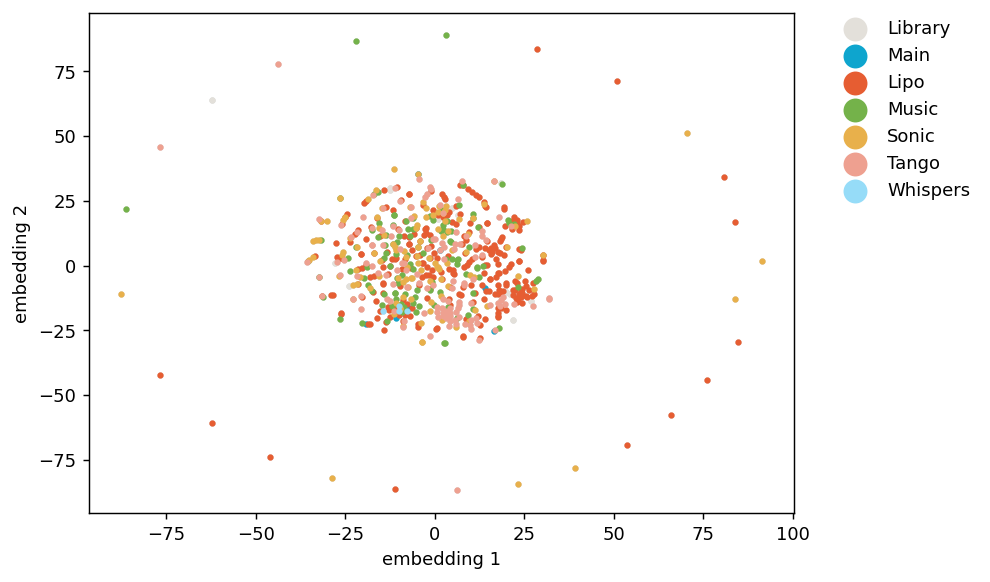

In [34]:
## Tsne based on protein space:
ACT_BINS   = ['Single (1)', 'Low (2-10)','Medium (11-25)',] #   'High (>25)'   # activity bins embedded
MAIN       = 'Main'      # the large library, cut down to the flavored libraries' scale
MAIN_PART  = 10         # Main compounds drawn at random, any activity; None keeps them all
SEED       = 0           # fixes the random draw
PERPLEXITY = 30          # t-SNE neighbourhood size
FLAV_COLS  = ['ember', 'azure', 'olive', 'gold', 'terracotta', 'sky_blue']   # SERAC_C keys, one per flavor
REST       = 'Library'   # compounds with no flavor

# Main cut to MAIN_PART random compounds, then the chosen bins, keeping compounds that carry a protein
main = cxp[cxp['Lib Flavor'].eq(MAIN)]
d = pd.concat([cxp[cxp['Lib Flavor'].ne(MAIN)],
               main if MAIN_PART is None else main.sample(MAIN_PART, random_state=SEED)])
d = d[d['activity'].isin(ACT_BINS) & d.select_dtypes('int8').any(axis=1)]

# proteins this subset ever hits: an all-zero column changes no Tanimoto distance
prot = d.select_dtypes('int8')
prot = prot.loc[:, prot.any()]
print(prot.shape)

# 2D t-SNE on the Tanimoto distance between the binary protein profiles
emb = TSNE(n_components=2, metric='precomputed', init='random', perplexity=PERPLEXITY,
           random_state=42).fit_transform(fn.tanimoto_distance_matrix(prot))
X = pd.DataFrame({'e1': emb[:, 0], 'e2': emb[:, 1], 'flavor': d['Lib Flavor'].fillna(REST).values},
                 index=d.index)

# colour by flavor: the rest of the library, then Main, drawn first so the flavors sit on top
flavs = sorted(X.loc[X['flavor'].ne(REST), 'flavor'].unique())
cmap = {REST: SERAC_C['paper'], **{f: SERAC_C[c] for f, c in zip(flavs, FLAV_COLS)}}
ax = stats_tools.plot_multi_class_to_embedding(X, label='flavor', e1='e1', e2='e2', s=6, colors=cmap,
                                               class_order=[REST, MAIN] + [f for f in flavs if f != MAIN],
                                               figsize=(7, 5), dpi=130)

X.head(3)